In [ ]:

# Import libraries for logarithmic regression
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:
df = pd.read_csv("/content/countries.csv")
df.head()

FileNotFoundError: [Errno 2] No such file or directory: '/content/countries.csv'

In [ ]:

import os

print(os.listdir("/content"))


['.config', 'sample_data']


In [2]:

import pandas as pd

df = pd.read_csv("/content/countries.csv")

print(df.head())


               Country                    Region  Population (millions)   HDI  \
0          Afghanistan  Middle East/Central Asia                  29.82  0.46   
1              Albania   Northern/Eastern Europe                   3.16  0.73   
2              Algeria                    Africa                  38.48  0.73   
3               Angola                    Africa                  20.82  0.52   
4  Antigua and Barbuda             Latin America                   0.09  0.78   

  GDP per Capita  Cropland Footprint  Grazing Footprint  Forest Footprint  \
0        $614.66                0.30               0.20              0.08   
1      $4,534.37                0.78               0.22              0.25   
2      $5,430.57                0.60               0.16              0.17   
3      $4,665.91                0.33               0.15              0.12   
4     $13,205.10                 NaN                NaN               NaN   

   Carbon Footprint  Fish Footprint  ...  Cropland

In [3]:

# Explore the countries dataset
print("DATASET SHAPE:")
print(df.shape)

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nMISSING VALUES:")
print(df.isnull().sum())


DATASET SHAPE:
(188, 21)

COLUMN NAMES:
['Country', 'Region', 'Population (millions)', 'HDI', 'GDP per Capita', 'Cropland Footprint', 'Grazing Footprint', 'Forest Footprint', 'Carbon Footprint', 'Fish Footprint', 'Total Ecological Footprint', 'Cropland', 'Grazing Land', 'Forest Land', 'Fishing Water', 'Urban Land', 'Total Biocapacity', 'Biocapacity Deficit or Reserve', 'Earths Required', 'Countries Required', 'Data Quality']

MISSING VALUES:
Country                            0
Region                             0
Population (millions)              0
HDI                               16
GDP per Capita                    15
Cropland Footprint                15
Grazing Footprint                 15
Forest Footprint                  15
Carbon Footprint                  15
Fish Footprint                    15
Total Ecological Footprint         0
Cropland                          15
Grazing Land                      15
Forest Land                       15
Fishing Water                     15

In [4]:

# Select the columns needed for regression
regression_df = df[
    ["GDP per Capita", "Total Ecological Footprint"]
].copy()

# Convert both columns to numeric
for column in regression_df.columns:
    regression_df[column] = pd.to_numeric(
        regression_df[column],
        errors="coerce"
    )

# Remove rows with missing values
regression_df = regression_df.dropna()

# Keep positive GDP values for logarithmic regression
regression_df = regression_df[
    regression_df["GDP per Capita"] > 0
]

print("Rows ready for regression:", len(regression_df))
print(regression_df.head())


Rows ready for regression: 0
Empty DataFrame
Columns: [GDP per Capita, Total Ecological Footprint]
Index: []


In [5]:

# Start again from the original dataset
regression_df = df[
    ["GDP per Capita", "Total Ecological Footprint"]
].copy()

# Remove commas, dollar signs, and extra spaces
regression_df["GDP per Capita"] = (
    regression_df["GDP per Capita"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("$", "", regex=False)
    .str.strip()
)

# Convert both columns to numbers
for column in regression_df.columns:
    regression_df[column] = pd.to_numeric(
        regression_df[column],
        errors="coerce"
    )

# Remove missing and nonpositive GDP values
regression_df = regression_df.dropna()
regression_df = regression_df[
    regression_df["GDP per Capita"] > 0
]

print("Rows ready for regression:", len(regression_df))
print(regression_df.head())


Rows ready for regression: 173
   GDP per Capita  Total Ecological Footprint
0          614.66                        0.79
1         4534.37                        2.21
2         5430.57                        2.12
3         4665.91                        0.93
4        13205.10                        5.38


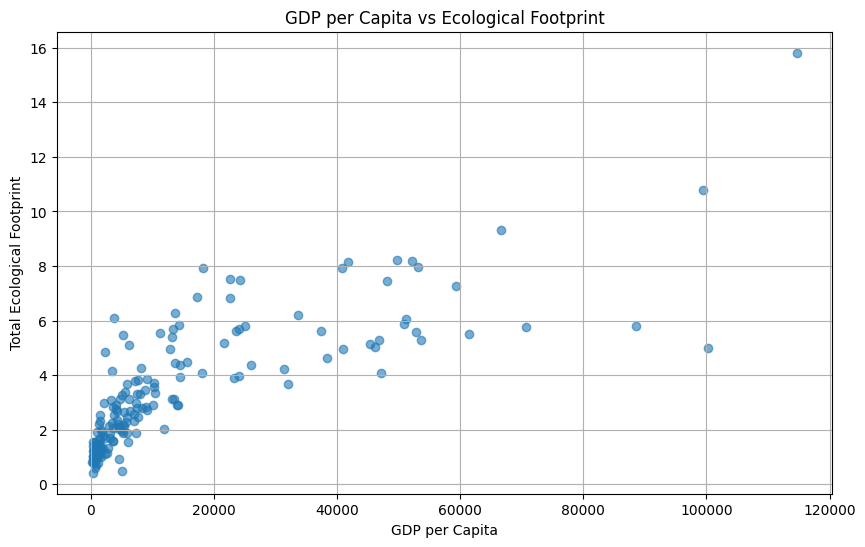

In [6]:

import matplotlib.pyplot as plt

# Create a scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    regression_df["GDP per Capita"],
    regression_df["Total Ecological Footprint"],
    alpha=0.6
)

plt.title("GDP per Capita vs Ecological Footprint")
plt.xlabel("GDP per Capita")
plt.ylabel("Total Ecological Footprint")

plt.grid(True)
plt.show()


In [7]:

# Define our input and target variables

X = regression_df[["GDP per Capita"]]
y = regression_df["Total Ecological Footprint"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)


Input shape: (173, 1)
Target shape: (173,)


In [8]:

from sklearn.linear_model import LinearRegression

# Create the linear regression model
model = LinearRegression()

# Train the model using our data
model.fit(X, y)

# Display the model's results
print("Intercept:", round(model.intercept_, 4))
print("Coefficient:", round(model.coef_[0], 6))
print("Model trained successfully!")


Intercept: 2.0104
Coefficient: 8.9e-05
Model trained successfully!


In [9]:

import pandas as pd

# Predict ecological footprint for different GDP levels
new_countries = pd.DataFrame({
    "GDP per Capita": [5000, 20000, 50000]
})

predictions = model.predict(new_countries)

for gdp, prediction in zip(
    new_countries["GDP per Capita"],
    predictions
):
    print(
        f"GDP: ${gdp:,} → "
        f"Predicted Footprint: {prediction:.2f}"
    )


GDP: $5,000 → Predicted Footprint: 2.46
GDP: $20,000 → Predicted Footprint: 3.79
GDP: $50,000 → Predicted Footprint: 6.46


In [10]:

# Generate predictions for our original dataset
y_pred = model.predict(X)

print("First 5 actual values:")
print(y.head())

print("\nFirst 5 predicted values:")
print(y_pred[:5])


First 5 actual values:
0    0.79
1    2.21
2    2.12
3    0.93
4    5.38
Name: Total Ecological Footprint, dtype: float64

First 5 predicted values:
[2.06508044 2.41389724 2.49365049 2.42560304 3.18550949]


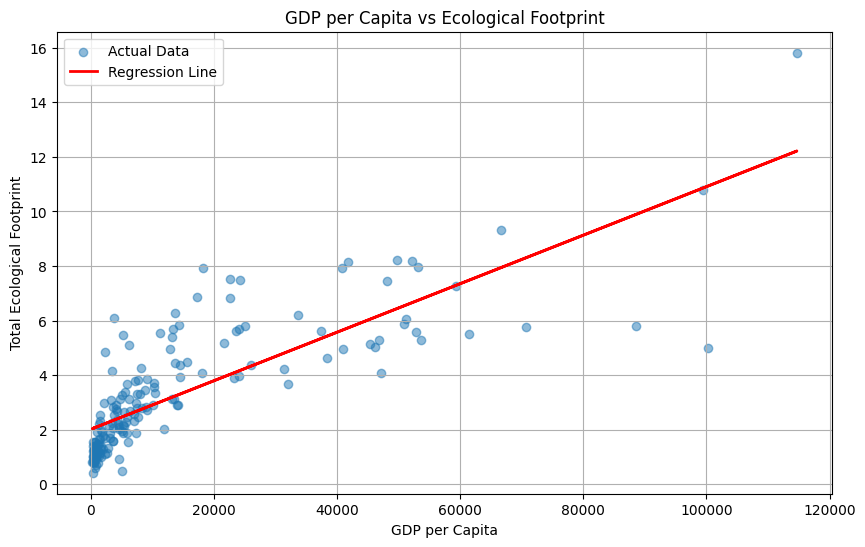

In [11]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot actual country data
plt.scatter(X["GDP per Capita"], y,
            alpha=0.5, label="Actual Data")

# Plot the regression line
plt.plot(X["GDP per Capita"], y_pred,
         color="red", linewidth=2,
         label="Regression Line")

plt.title("GDP per Capita vs Ecological Footprint")
plt.xlabel("GDP per Capita")
plt.ylabel("Total Ecological Footprint")

plt.legend()
plt.grid(True)
plt.show()


In [12]:

from sklearn.metrics import r2_score

# Calculate model performance
r2 = r2_score(y, y_pred)

print(f"R² Score: {r2:.4f}")
print(f"Variance Explained: {r2 * 100:.2f}%")


R² Score: 0.6391
Variance Explained: 63.91%


In [13]:

import numpy as np

# Create a logarithmic version of GDP
X_log = np.log(
    regression_df[["GDP per Capita"]]
)

print("Original GDP:")
print(X.head())

print("\nLog-Transformed GDP:")
print(X_log.head())


Original GDP:
   GDP per Capita
0          614.66
1         4534.37
2         5430.57
3         4665.91
4        13205.10

Log-Transformed GDP:
   GDP per Capita
0        6.421069
1        8.419441
2        8.599799
3        8.448038
4        9.488358


In [14]:

from sklearn.linear_model import LinearRegression

# Create our Linear-Log model
log_model = LinearRegression()

# Train using logarithmic GDP
log_model.fit(X_log, y)

# Generate predictions
y_log_pred = log_model.predict(X_log)

print("Linear-Log model trained successfully!")
print("Intercept:", round(log_model.intercept_, 4))
print("Coefficient:", round(log_model.coef_[0], 4))


Linear-Log model trained successfully!
Intercept: -7.5966
Coefficient: 1.2685


In [15]:

from sklearn.metrics import r2_score

# Compare model performance
linear_r2 = r2_score(y, y_pred)
log_r2 = r2_score(y, y_log_pred)

print(f"Normal Linear R²: {linear_r2:.4f}")
print(f"Linear-Log R²: {log_r2:.4f}")

if log_r2 > linear_r2:
    print("Linear-Log Regression fits better!")
else:
    print("Normal Linear Regression fits better!")


Normal Linear R²: 0.6391
Linear-Log R²: 0.6718
Linear-Log Regression fits better!


In [16]:

import numpy as np

# Check that ecological footprint values are positive
print("Minimum footprint:", y.min())

# Log-transform the target variable
y_log = np.log(y.where(y > 0))

print("\nOriginal Ecological Footprint:")
print(y.head())

print("\nLog-Transformed Ecological Footprint:")
print(y_log.head())

print("\nMissing values after transformation:")
print(y_log.isna().sum())


Minimum footprint: 0.42

Original Ecological Footprint:
0    0.79
1    2.21
2    2.12
3    0.93
4    5.38
Name: Total Ecological Footprint, dtype: float64

Log-Transformed Ecological Footprint:
0   -0.235722
1    0.792993
2    0.751416
3   -0.072571
4    1.682688
Name: Total Ecological Footprint, dtype: float64

Missing values after transformation:
0


In [17]:

from sklearn.linear_model import LinearRegression

# Create and train the Log-Linear model
log_linear_model = LinearRegression()
log_linear_model.fit(X, y_log)

# Predict logarithmic ecological footprints
y_log_linear_pred = log_linear_model.predict(X)

print("Log-Linear model trained successfully!")
print("Intercept:", round(log_linear_model.intercept_, 4))
print("Coefficient:", round(log_linear_model.coef_[0], 6))


Log-Linear model trained successfully!
Intercept: 0.6123
Coefficient: 2.4e-05


In [18]:

from sklearn.metrics import r2_score
import numpy as np

# Convert predictions back to the original scale
y_log_linear_original = np.exp(y_log_linear_pred)

# Calculate R² on the original scale
log_linear_r2 = r2_score(y, y_log_linear_original)

print("MODEL COMPARISON")
print("----------------------------")
print(f"Normal Linear R²: {linear_r2:.4f}")
print(f"Linear-Log R²: {log_r2:.4f}")
print(f"Log-Linear R²: {log_linear_r2:.4f}")


MODEL COMPARISON
----------------------------
Normal Linear R²: 0.6391
Linear-Log R²: 0.6718
Log-Linear R²: 0.0586


In [19]:

# Create a binary variable for high-income countries
regression_df["High Income"] = (
    regression_df["GDP per Capita"] >= 20000
).astype(int)

# Display the first 10 rows
print(regression_df[
    ["GDP per Capita", "High Income"]
].head(10))

# Count countries in each group
print("\nHigh Income Counts:")
print(regression_df["High Income"].value_counts())


    GDP per Capita  High Income
0           614.66            0
1          4534.37            0
2          5430.57            0
3          4665.91            0
4         13205.10            0
5         13540.00            0
6          3426.39            0
8         66604.20            1
9         51274.10            1
10         7106.04            0

High Income Counts:
High Income
0    135
1     38
Name: count, dtype: int64


In [20]:

from sklearn.linear_model import LinearRegression

# Binary input variable
X_binary = regression_df[["High Income"]]

# Create and train the model
binary_model = LinearRegression()
binary_model.fit(X_binary, y_log)

# Generate predictions
binary_predictions = binary_model.predict(X_binary)

print("Log-Binary model trained successfully!")
print("Intercept:", round(binary_model.intercept_, 4))
print("Coefficient:", round(binary_model.coef_[0], 4))


Log-Binary model trained successfully!
Intercept: 0.7083
Coefficient: 1.0904


In [21]:

import numpy as np

# Convert the coefficient into a percentage difference
percentage_difference = (
    np.exp(binary_model.coef_[0]) - 1
) * 100

# Calculate predicted ecological footprint
# for each income group
low_income = np.exp(binary_model.intercept_)

high_income = np.exp(
    binary_model.intercept_ + binary_model.coef_[0]
)

print("LOG-BINARY REGRESSION RESULTS")
print("-----------------------------")
print(f"Lower-Income Group: {low_income:.2f}")
print(f"High-Income Group: {high_income:.2f}")
print(f"Percentage Difference: {percentage_difference:.2f}%")


LOG-BINARY REGRESSION RESULTS
-----------------------------
Lower-Income Group: 2.03
High-Income Group: 6.04
Percentage Difference: 197.54%


In [22]:

import numpy as np

# Log-transform both variables
X_loglog = np.log(
    regression_df[["GDP per Capita"]]
)

y_loglog = np.log(
    regression_df["Total Ecological Footprint"]
)

print("Log-Transformed GDP:")
print(X_loglog.head())

print("\nLog-Transformed Ecological Footprint:")
print(y_loglog.head())


Log-Transformed GDP:
   GDP per Capita
0        6.421069
1        8.419441
2        8.599799
3        8.448038
4        9.488358

Log-Transformed Ecological Footprint:
0   -0.235722
1    0.792993
2    0.751416
3   -0.072571
4    1.682688
Name: Total Ecological Footprint, dtype: float64


In [23]:

from sklearn.linear_model import LinearRegression

# Create the Log-Log regression model
loglog_model = LinearRegression()

# Train using both log-transformed variables
loglog_model.fit(X_loglog, y_loglog)

# Generate predictions
y_loglog_pred = loglog_model.predict(X_loglog)

print("Log-Log model trained successfully!")
print("Intercept:", round(loglog_model.intercept_, 4))
print("Coefficient:", round(loglog_model.coef_[0], 4))


Log-Log model trained successfully!
Intercept: -2.6007
Coefficient: 0.4139


In [24]:

from sklearn.metrics import r2_score
import numpy as np

# Convert Log-Log predictions to original scale
y_loglog_original = np.exp(y_loglog_pred)

# Calculate R² on the original scale
loglog_r2 = r2_score(y, y_loglog_original)

print("FINAL REGRESSION COMPARISON")
print("----------------------------")
print(f"Normal Linear R²: {linear_r2:.4f}")
print(f"Linear-Log R²: {log_r2:.4f}")
print(f"Log-Linear R²: {log_linear_r2:.4f}")
print(f"Log-Log R²: {loglog_r2:.4f}")


FINAL REGRESSION COMPARISON
----------------------------
Normal Linear R²: 0.6391
Linear-Log R²: 0.6718
Log-Linear R²: 0.0586
Log-Log R²: 0.7218
